# Powerlifting Lift Judge: squat walkthrough

**Author:** Abdulaziz Abdulhadi · GA Data Science Bootcamp (DSB-PT-4) capstone

## Problem statement
In powerlifting, three referees decide by eye whether a lift meets the IPF rules. Close calls
(especially squat depth) are subjective and often disputed, and lifters training alone have no
referee at all. Using phone video and pose estimation, we want to build a system that judges each
rep against the IPF rules and **explains** its decision, so lifters and coaches get consistent,
objective feedback.

> business problem → why it matters → what ML will do

## Audience
- **Lifters**: check training sets before a meet ("was that deep enough?")
- **Coaches**: review athletes' technique remotely and consistently
- **Federations / meet organisers**: an objective second opinion on close calls and referee training

## Goals
- Extract the lifter's body keypoints from video with a pretrained pose model (YOLO26-pose)
- Turn keypoints into signals (depth, joint angles, velocities) and split sets into reps
- Encode the IPF squat rules as measurable checks with red / blue / yellow cards
- Calibrate thresholds and train a rep classifier on human-labelled videos (notebook 02)
- Report recall on no-lifts and show an annotated demo video

## Approach

```
video → pose keypoints → signals → reps → IPF rule checks → verdict + reason
```

| Step | Module | GA topic it uses |
|---|---|---|
| keypoints → table | `keypoints.py` | pandas DataFrames |
| smoothing, angles, velocities | `signals.py` | feature engineering |
| rep splitting | `reps.py` | signal peaks |
| rules | `rules/squat.py` | domain-driven features |
| calibration + classifier | notebook 02 | classification metrics, imbalanced data, pipelines, NN |

## Data
- **Source:** my own recordings and gym partners' sets (side view, with consent), plus the
  Fitness-AQA dataset on request. Real videos are kept out of git (see `data/README.md`).
- **Size:** one row per **frame**: 300 videos × ~150 frames ≈ 45k rows; 17 keypoints × 3 values = 51 raw columns.
- Until the recordings are labelled, this notebook uses **synthetic squats** from
  `liftjudge.synthetic`, which follow the same geometry (shin + thigh + torso).

## Data dictionary (per-frame signals)

| Column | Type | Description |
|---|---|---|
| `time_s` | float | time from the start of the video |
| `<joint>_x`, `<joint>_y` | float | smoothed pixel coordinates (shoulder, elbow, wrist, hip, knee, ankle) |
| `thigh_px` | float | thigh length in pixels, used to normalise everything |
| `depth` | float | `(hip_y − knee_y) / thigh`, > 0 means hip joint below knee joint |
| `hip_height` | float | hips above the ankles, in thighs |
| `hip_vel` | float | hip vertical speed (thighs/s), > 0 means moving down |
| `knee_angle`, `hip_angle`, `elbow_angle` | float | joint angles in degrees, 180 = straight |
| `leg_conf` | float | mean keypoint confidence of hip, knee, ankle |

In [1]:
import sys
from pathlib import Path
# make `liftjudge` importable without installing (pip install -e . also works)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from liftjudge import analyze_pose
from liftjudge.synthetic import make_squat
from liftjudge.rules import SquatConfig

## 1. A set of three squats
`depth_deg` is how far the thigh goes below horizontal at the bottom (negative = above parallel).

In [2]:
pose = make_squat(depth_deg=15, reps=3, seed=1)
res = analyze_pose(pose, "squat")
sig = res.signals
print(f"{len(sig)} frames at {pose.fps:.0f} fps, side used: {sig.attrs['side']}")
sig.head()

303 frames at 30 fps, side used: left


,time_s,shoulder_x,shoulder_y,elbow_x,elbow_y,wrist_x,wrist_y,hip_x,hip_y,knee_x,...,ankle_y,thigh_px,depth,hip_height,hip_vel,wrist_vel,knee_angle,hip_angle,elbow_angle,leg_conf
0,0.000000,599.197293,239.668225,559.371891,299.820685,589.407221,249.515102,599.961633,500.612311,602.304032,...,900.777064,199.897301,-0.998226,2.001852,-0.087935,0.067810,178.962373,179.495272,2.667888,0.9
1,0.033333,599.916070,239.928190,559.853163,298.855876,589.788130,249.966937,600.578373,500.026379,601.428606,...,900.549394,199.897301,-0.997948,2.003644,-0.069049,0.046829,179.421933,179.901696,2.731071,0.9
2,0.066667,600.327551,240.099625,560.198723,298.327562,590.085367,250.139164,600.853641,499.692137,600.822625,...,900.372379,199.897301,-0.997522,2.004430,-0.031276,0.004866,179.713507,179.874972,2.766006,0.9
3,0.100000,600.431735,240.182530,560.408570,298.235743,590.298931,250.031782,600.787438,499.609585,600.486088,...,900.246019,199.897301,-0.996948,2.004211,0.008494,-0.061619,179.837030,179.834802,2.780970,0.9
4,0.133333,599.881391,240.410086,560.688688,298.834127,590.870354,249.318000,600.476105,499.805336,600.299650,...,899.874727,199.897301,-0.997293,2.001375,0.114274,-0.083177,179.898812,179.817925,2.491318,0.9


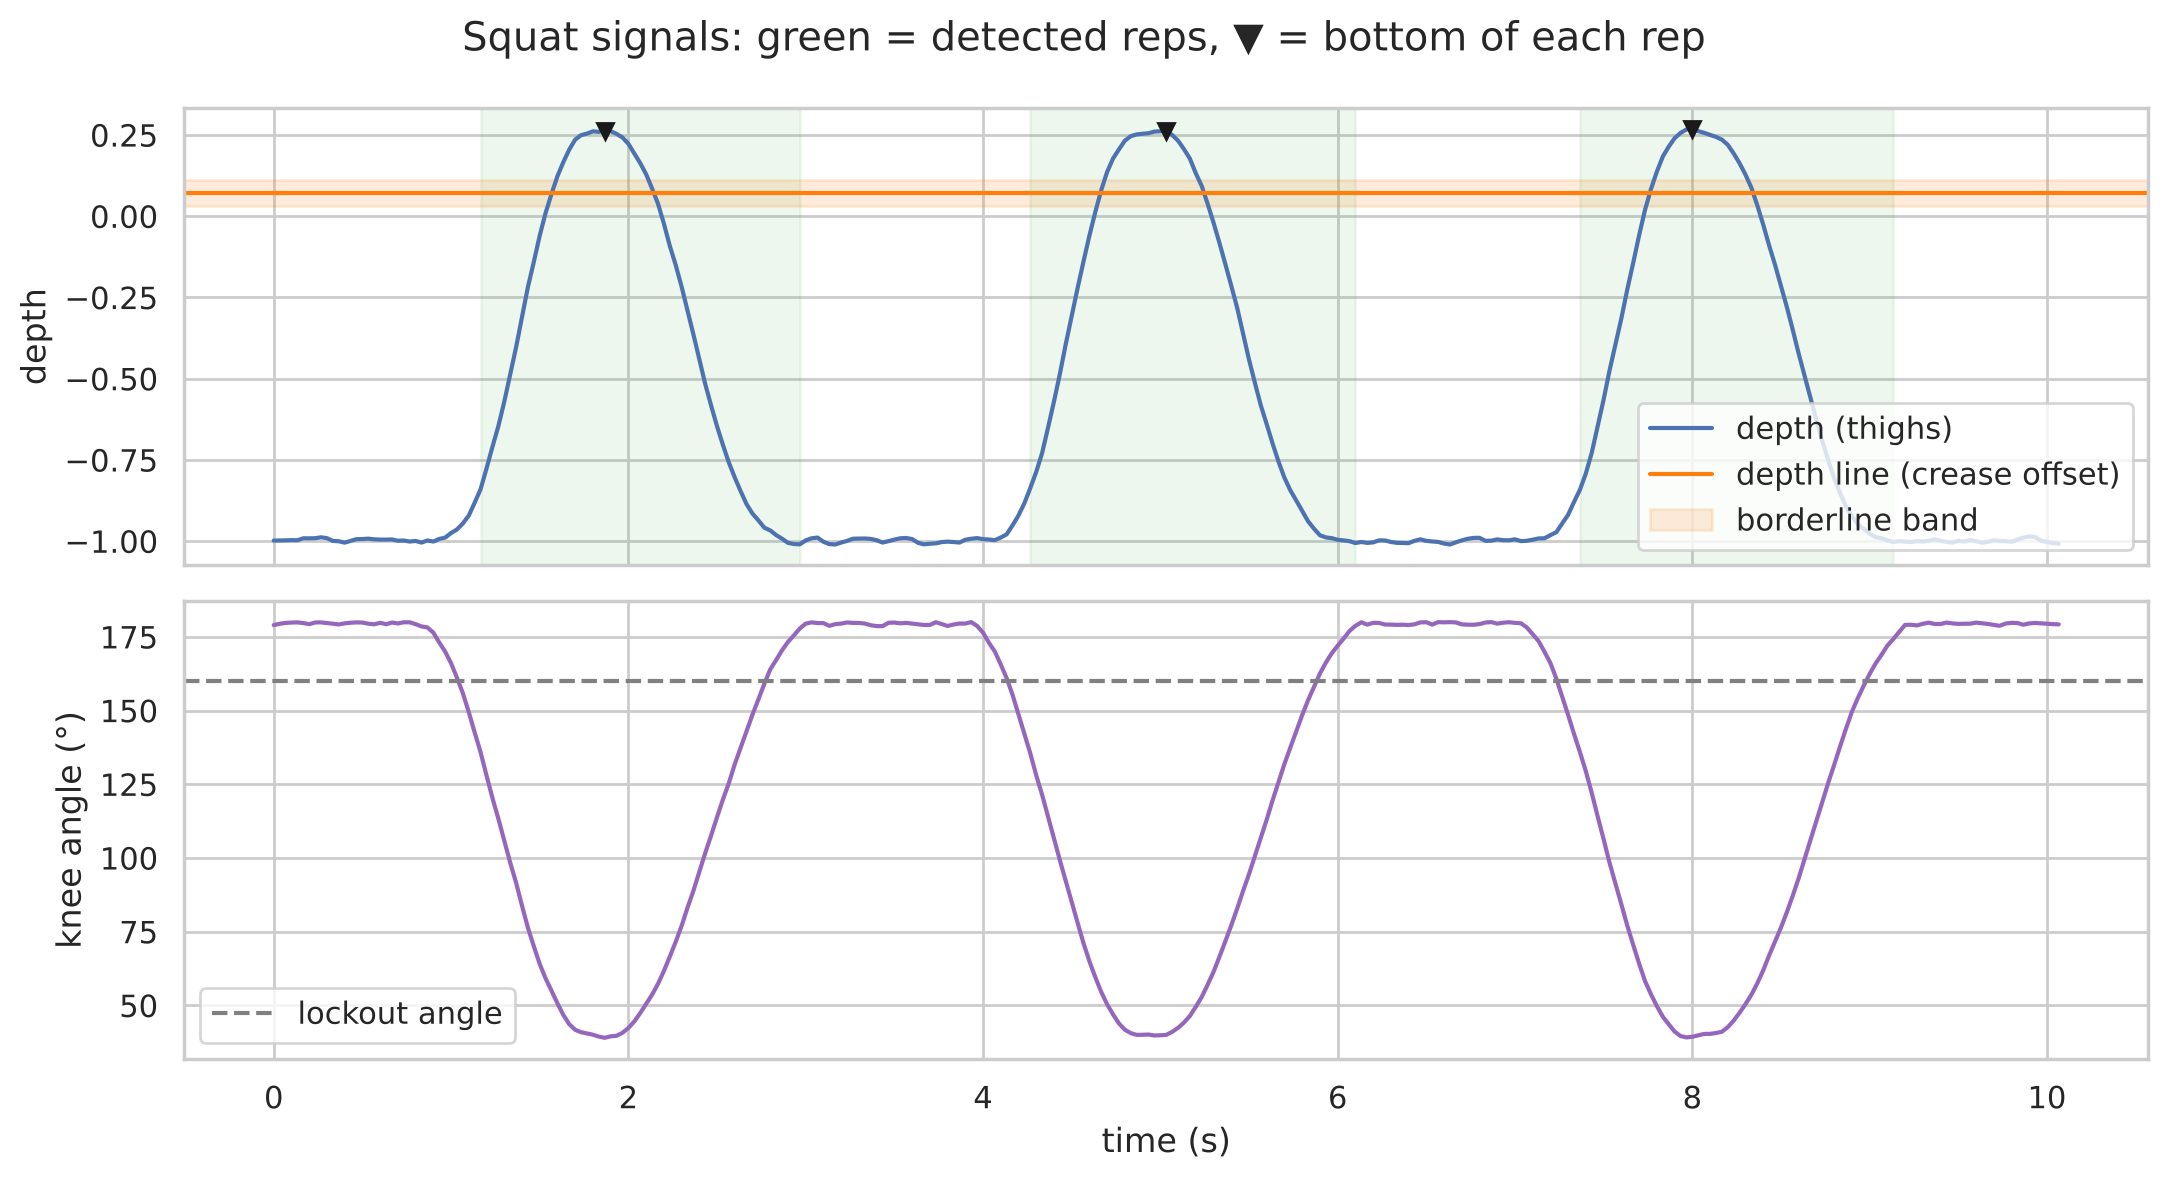

In [3]:
cfg = SquatConfig()
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(sig.time_s, sig.depth, label="depth (thighs)")
ax[0].axhline(cfg.crease_offset, color="tab:orange", label="depth line (crease offset)")
ax[0].axhspan(cfg.crease_offset - cfg.borderline_band, cfg.crease_offset + cfg.borderline_band,
              color="tab:orange", alpha=0.15, label="borderline band")
for v in res.verdicts:
    ax[0].axvspan(sig.time_s[v.start], sig.time_s[v.end], color="tab:green", alpha=0.08)
    ax[0].plot(sig.time_s[v.bottom], sig.depth[v.bottom], "v", color="k")
ax[0].set_ylabel("depth"); ax[0].legend(loc="lower right")
ax[1].plot(sig.time_s, sig.knee_angle, color="tab:purple")
ax[1].axhline(cfg.lockout_knee_angle, ls="--", color="grey", label="lockout angle")
ax[1].set_ylabel("knee angle (°)"); ax[1].set_xlabel("time (s)"); ax[1].legend()
plt.suptitle("Squat signals: green = detected reps, ▼ = bottom of each rep")
plt.tight_layout()

In [4]:
print(res.summary())

Rep 1: GOOD LIFT
   ok Depth: hip crease below the knee (+0.19 thighs)
   ok Knees locked at the start (178°)
   ok Knees locked at the finish (180°)
   ok Single, controlled bottom position
   ok Continuous ascent, no downward movement
   ok Feet stayed in place
Rep 2: GOOD LIFT
   ok Depth: hip crease below the knee (+0.19 thighs)
   ok Knees locked at the start (179°)
   ok Knees locked at the finish (180°)
   ok Single, controlled bottom position
   ok Continuous ascent, no downward movement
   ok Feet stayed in place
Rep 3: GOOD LIFT
   ok Depth: hip crease below the knee (+0.20 thighs)
   ok Knees locked at the start (178°)
   ok Knees locked at the finish (180°)
   ok Single, controlled bottom position
   ok Continuous ascent, no downward movement
   ok Feet stayed in place


## 2. The same pipeline on faulty lifts
Each case breaks one IPF rule. The judge should give the right card and say why.

In [5]:
cases = {
    "deep":                 dict(depth_deg=15),
    "high":                 dict(depth_deg=-10),
    "on the line":          dict(depth_deg=4),
    "double bounce":        dict(depth_deg=15, bounce=True),
    "downward on ascent":   dict(depth_deg=15, ascent_dip=0.12),
    "no lockout at finish": dict(depth_deg=15, finish_s=0.25),
    "step":                 dict(depth_deg=15, step_px=45),
}
rows = []
for name, kw in cases.items():
    v = analyze_pose(make_squat(**kw), "squat").verdicts[0]
    failed = [c.message for c in v.checks if c.status.value != "pass"]
    rows.append({"case": name, "verdict": v.label, "cards": ", ".join(c.value for c in v.cards) or "-",
                 "reason": failed[0] if failed else "all checks passed"})
pd.DataFrame(rows)

,case,verdict,cards,reason
0,deep,GOOD LIFT,-,all checks passed
1,high,NO LIFT,red,High: hip crease did not go below the top of t...
2,on the line,BORDERLINE,-,Depth borderline (+0.00 thighs): too close to ...
3,double bounce,NO LIFT,blue,Double bounce: hips rose 0.39 thighs then drop...
4,downward on ascent,NO LIFT,blue,Downward movement during the ascent (0.19 thighs)
5,no lockout at finish,NO LIFT,blue,Knees not locked at the finish: 146° < 160°
6,step,NO LIFT,yellow,Feet moved 0.24 thighs (step)


Text(0.5, 1.0, 'What each fault looks like in the depth signal')

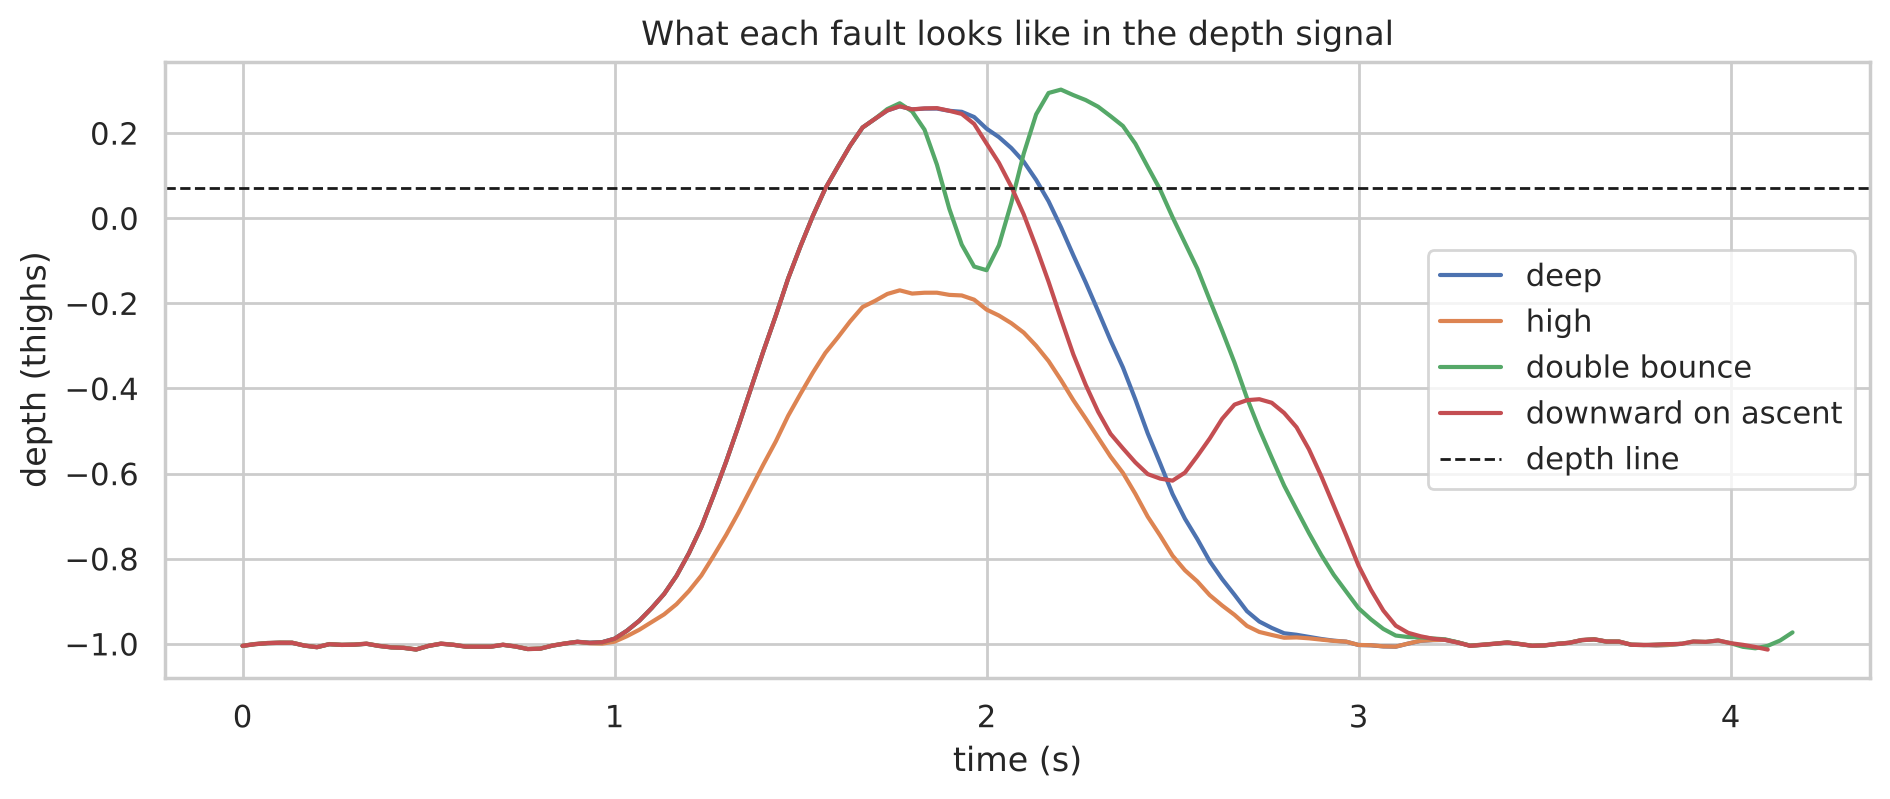

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
for name in ["deep", "high", "double bounce", "downward on ascent"]:
    s = analyze_pose(make_squat(**cases[name]), "squat").signals
    ax.plot(s.time_s, s.depth, label=name)
ax.axhline(SquatConfig().crease_offset, color="k", ls="--", lw=1, label="depth line")
ax.set_xlabel("time (s)"); ax.set_ylabel("depth (thighs)"); ax.legend()
ax.set_title("What each fault looks like in the depth signal")

## 3. Run it on a real video
Put a side-view squat video in `data/raw/squat/` and set the path. The first run downloads
`yolo26n-pose.pt` and caches the keypoints next to the video.

In [7]:
VIDEO = ROOT / "data/raw/squat/my_squat.mp4"   # <- change me

if VIDEO.exists():
    from liftjudge import analyze
    from liftjudge.render import render_video
    real = analyze(VIDEO, "squat")
    print(real.summary())
    render_video(VIDEO, ROOT / "results" / f"{VIDEO.stem}_judged.mp4",
                 real.pose, real.signals, real.verdicts)
else:
    print(f"No video at {VIDEO}: record one (see data/README.md) and re-run this cell.")

No video at /home/claude/powerlifting-lift-judge/data/raw/squat/my_squat.mp4: record one (see data/README.md) and re-run this cell.


## Next
- Record and label ~150 reps (`data/labels.csv`)
- Notebook 02: calibrate the crease offset and train a rep classifier
- Phase 2b: barbell tracking for the bench press and deadlift